In [11]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.366 seconds
All requested packages already installed.


In [12]:
!pip install numpy

mambajs 0.21.4

Process pip requirements ...

Requirement numpy already handled by conda/micromamba/mamba.


In [13]:
!pip install pandas

mambajs 0.21.4

Process pip requirements ...

Requirement pandas already handled by conda/micromamba/mamba.


In [14]:
!pip install matplotlib

mambajs 0.21.4

Process pip requirements ...

Requirement matplotlib already handled by conda/micromamba/mamba.


In [15]:
!pip install seaborn

mambajs 0.21.4

Process pip requirements ...

Requirement seaborn already satisfied.


In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 100)

print("Libraries imported successfully!")


Libraries imported successfully!


EMPLOYEE ATTRITION ANALYSIS

1. FIRST FIVE EMPLOYEE RECORDS


,Age,Attrition,Department,JobRole,JobSatisfaction,MonthlyIncome,OverTime,YearsAtCompany
0,37,No,Sales,Sales Representative,1,12383,No,4
1,49,Yes,Research & Development,Laboratory Technician,4,3992,No,0
2,53,No,Sales,Sales Representative,4,7279,No,13
3,41,No,Sales,Sales Representative,2,5496,Yes,0
4,34,Yes,Research & Development,Laboratory Technician,3,5825,Yes,2


Dataset shape (rows, columns): (1470, 8)

2. MISSING VALUES IN EACH COLUMN


,Missing Values
Age,0
Attrition,0
Department,0
JobRole,0
JobSatisfaction,0
MonthlyIncome,0
OverTime,0
YearsAtCompany,0


Number of duplicate rows: 0

3. OVERALL ATTRITION SUMMARY


...

Attrition,No,Yes,Attrition Rate (%)
Department,,,
Human Resources,56,11,16.42
Research & Development,796,168,17.43
Sales,347,92,20.96



5. ATTRITION PERCENTAGE BY OVERTIME


Attrition,No,Yes
OverTime,,
No,87.99,12.01
Yes,65.56,34.44



6. AVERAGE INCOME AND YEARS AT COMPANY


,MonthlyIncome,YearsAtCompany
Attrition,,
No,8247.40,5.62
Yes,6794.48,3.77


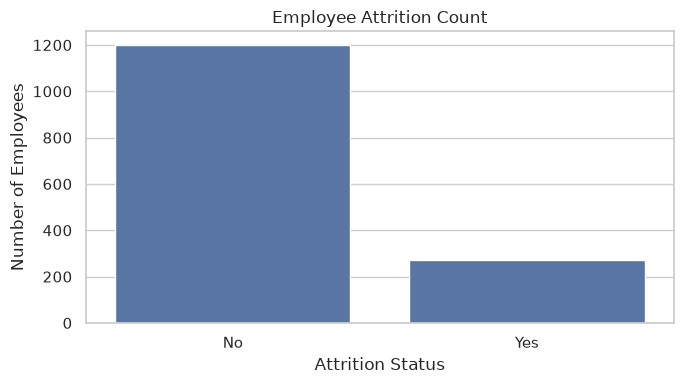

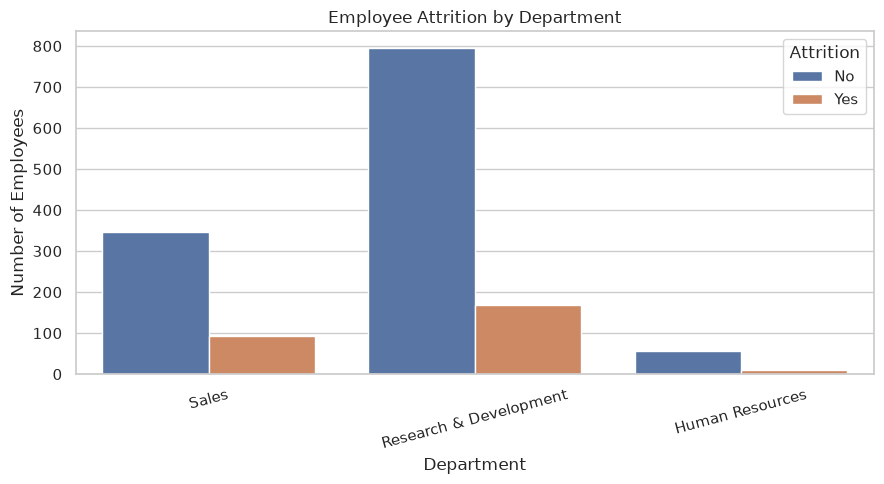

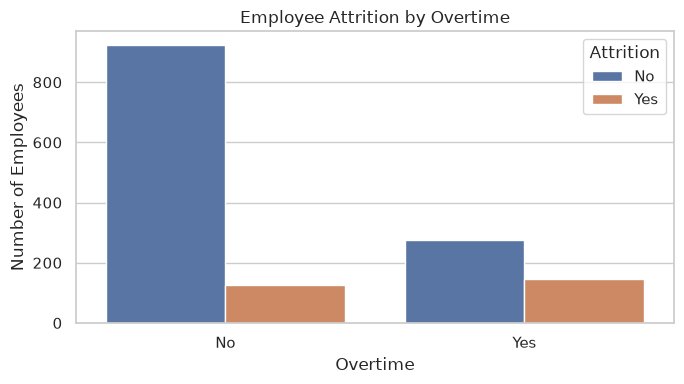

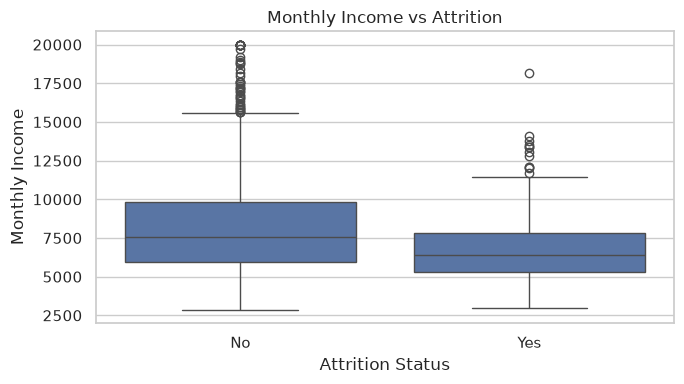

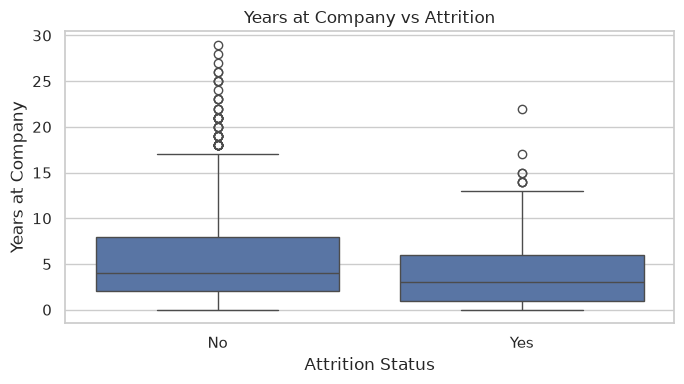


ANALYSIS COMPLETED SUCCESSFULLY!
Total Employees Analysed: 1470
Employees Who Left: 271
Attrition Rate: 18.44 %
All five graphs have been displayed.


In [17]:
# EMPLOYEE ATTRITION ANALYSIS PROJECT

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 100)


# 1. Generate the dataset

def generate_employee_data(n=1470, seed=42):
    """Creates a sample employee dataset with n records."""

    rng = np.random.default_rng(seed)

    department = rng.choice(
        [
            "Research & Development",
            "Sales",
            "Human Resources"
        ],
        size=n,
        p=[0.654, 0.303, 0.043]
    )

    # Job roles according to department
    roles_by_department = {
        "Research & Development": [
            "Research Scientist",
            "Laboratory Technician"
        ],
        "Sales": [
            "Sales Executive",
            "Sales Representative"
        ],
        "Human Resources": [
            "HR Executive",
            "HR Assistant"
        ]
    }

    role = np.empty(n, dtype=object)

    for dept, roles in roles_by_department.items():
        mask = department == dept
        role[mask] = rng.choice(
            roles,
            size=mask.sum()
        )

    overtime = rng.choice(
        ["Yes", "No"],
        size=n,
        p=[0.283, 0.717]
    )

    age = np.clip(
        rng.normal(37, 9, n).round(),
        20,
        60
    ).astype(int)

    # Years at company cannot exceed possible working years
    years = np.minimum(
        rng.exponential(6.5, n).round(),
        age - 20
    ).astype(int)

    income = np.clip(
        2000
        + years * 250
        + rng.lognormal(8.3, 0.6, n),
        1000,
        20000
    ).round().astype(int)

    job_sat = rng.integers(1, 5, n)

    # Calculate attrition probability
    z = (
        -1.6
        + 1.2 * (overtime == "Yes")
        - 0.00018 * (income - 6500)
        - 0.07 * years
        + 0.30 * (department == "Sales")
        + 0.20 * (department == "Human Resources")
        - 0.15 * (job_sat - 2.5)
    )

    prob = 1 / (1 + np.exp(-z))

    attrition = np.where(
        rng.random(n) < prob,
        "Yes",
        "No"
    )

    return pd.DataFrame({
        "Age": age,
        "Attrition": attrition,
        "Department": department,
        "JobRole": role,
        "JobSatisfaction": job_sat,
        "MonthlyIncome": income,
        "OverTime": overtime,
        "YearsAtCompany": years
    })


# 2. Generate employee data

print("=" * 55)
print("EMPLOYEE ATTRITION ANALYSIS")
print("=" * 55)

df = generate_employee_data()

print("\n1. FIRST FIVE EMPLOYEE RECORDS")
display(df.head())

print("Dataset shape (rows, columns):", df.shape)


# 3. Inspect data quality

print("\n2. MISSING VALUES IN EACH COLUMN")
display(df.isnull().sum().to_frame("Missing Values"))

print("Number of duplicate rows:", df.duplicated().sum())


# 4. Clean the data

df = df.drop_duplicates()


# 5. Overall attrition summary

total_employees = len(df)

employees_left = (
    df["Attrition"] == "Yes"
).sum()

attrition_rate = (
    employees_left / total_employees
) * 100

summary = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Employees Who Left",
        "Employees Who Stayed",
        "Attrition Rate (%)"
    ],
    "Value": [
        total_employees,
        employees_left,
        total_employees - employees_left,
        round(attrition_rate, 2)
    ]
})

print("\n3. OVERALL ATTRITION SUMMARY")
display(summary)


# 6. Department-wise attrition

dept_table = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

dept_table["Attrition Rate (%)"] = (
    dept_table["Yes"]
    / (dept_table["Yes"] + dept_table["No"])
    * 100
).round(2)

print("\n4. DEPARTMENT-WISE ATTRITION")
display(dept_table)


# 7. Overtime-wise attrition

overtime_table = (
    pd.crosstab(
        df["OverTime"],
        df["Attrition"],
        normalize="index"
    ) * 100
).round(2)

print("\n5. ATTRITION PERCENTAGE BY OVERTIME")
display(overtime_table)


# 8. Income and experience analysis

average_table = (
    df.groupby("Attrition")[
        ["MonthlyIncome", "YearsAtCompany"]
    ].mean().round(2)
)

print("\n6. AVERAGE INCOME AND YEARS AT COMPANY")
display(average_table)


# 9. Visualizations

# Graph 1: Overall employee attrition count

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Attrition"
)

plt.title("Employee Attrition Count")
plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()
plt.close()


# Graph 2: Attrition by department

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Department",
    hue="Attrition"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
plt.close()


# Graph 3: Attrition by overtime

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="OverTime",
    hue="Attrition"
)

plt.title("Employee Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()
plt.close()


# Graph 4: Monthly income comparison

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Monthly Income vs Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Monthly Income")
plt.tight_layout()
plt.show()
plt.close()


# Graph 5: Years at company comparison

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="Attrition",
    y="YearsAtCompany"
)

plt.title("Years at Company vs Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Years at Company")
plt.tight_layout()
plt.show()
plt.close()


# 10. Final message

print("\n" + "=" * 55)
print("ANALYSIS COMPLETED SUCCESSFULLY!")
print("Total Employees Analysed:", total_employees)
print("Employees Who Left:", employees_left)
print("Attrition Rate:", round(attrition_rate, 2), "%")
print("All five graphs have been displayed.")
print("=" * 55)